# 03 Explore movies, tags and links

The ratings tell us *who liked what*. The other three files describe the **movies themselves**, and that is the raw material for the content-based model:

| File | What it holds |
|---|---|
| `movies.csv` | `movieId`, `title` (with the year), `genres` (like `Action\|Sci-Fi`) |
| `tags.csv` | free-text tags that some users attached to movies |
| `links.csv` | `imdbId` and `tmdbId`, to fetch extra data (plot, poster) from TMDB |

**Goal:** find out what we can build content features from, and above all whether the *rarely rated* movies (the cold-start group from notebook 01) have any content to work with.

In [1]:
import sys
sys.path.insert(0, "..")  # so that `src` can be imported from the notebooks folder

import matplotlib.pyplot as plt
import pandas as pd

from src.download_data import EXTRACTED_DIR

movies = pd.read_csv(EXTRACTED_DIR / "movies.csv")
tags = pd.read_csv(EXTRACTED_DIR / "tags.csv")
links = pd.read_csv(EXTRACTED_DIR / "links.csv")
ratings = pd.read_csv(EXTRACTED_DIR / "ratings.csv")

## 1. Movies

In [2]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
# rows and columns
movies.shape

(9742, 3)

In [4]:
# column types and missing values
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


### Genres

A movie has several genres packed into one string, separated by `|`. To count them we split the string and give every (movie, genre) pair its own row (`explode`). Movies with `(no genres listed)` are left out of that table.

In [5]:
NO_GENRES = "(no genres listed)"
print("Movies with no genres:", (movies["genres"] == NO_GENRES).sum())

# One row per (movie, genre): "Action|Sci-Fi" becomes two rows
movie_genres = (
    movies[movies["genres"] != NO_GENRES]
    .assign(genre=lambda df: df["genres"].str.split("|"))
    .explode("genre")[["movieId", "genre"]]
)
genre_counts = movie_genres["genre"].value_counts()
print("Distinct genres:", len(genre_counts))
genre_counts

Movies with no genres: 34
Distinct genres: 19


genre
Drama          4361
Comedy         3756
Thriller       1894
Action         1828
Romance        1596
Adventure      1263
Crime          1199
Sci-Fi          980
Horror          978
Fantasy         779
Children        664
Animation       611
Mystery         573
Documentary     440
War             382
Musical         334
Western         167
IMAX            158
Film-Noir        87
Name: count, dtype: int64

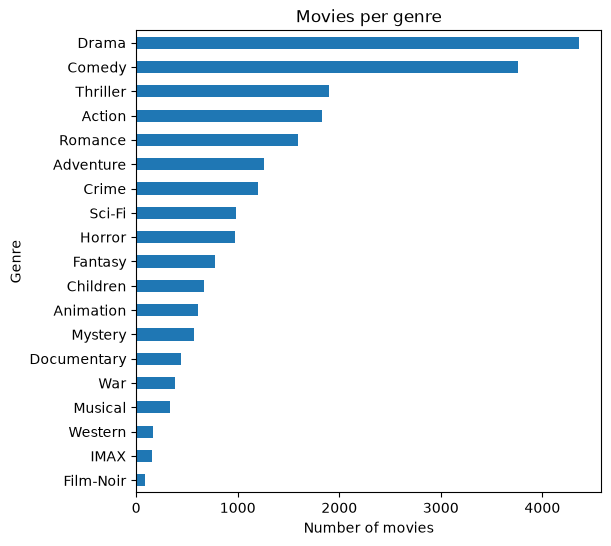

In [6]:
genre_counts.sort_values().plot(kind="barh", figsize=(6, 6))
plt.title("Movies per genre")
plt.xlabel("Number of movies")
plt.ylabel("Genre")
plt.show()

In [7]:
# How many genres does a movie have?
genres_per_movie = movie_genres.groupby("movieId").size()
genres_per_movie.value_counts().sort_index()

1     2817
2     3218
3     2338
4      987
5      271
6       63
7       12
8        1
10       1
Name: count, dtype: int64

### Year

The release year is only inside the title, like `Toy Story (1995)`. A regular expression pulls out the four digits in parentheses at the end of the title.

In [8]:
years = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0]
movies["year"] = pd.to_numeric(years).astype("Int64")  # Int64 allows missing values

print("Titles without a parsable year:", movies["year"].isna().sum())
movies[movies["year"].isna()][["movieId", "title"]]

Titles without a parsable year: 13


,movieId,title
6059,40697,Babylon 5
9031,140956,Ready Player One
9091,143410,Hyena Road
9138,147250,The Adventures of Sherlock Holmes and Doctor W...
9179,149334,Nocturnal Animals
9259,156605,Paterson
9367,162414,Moonlight
9448,167570,The OA
9514,171495,Cosmos
9515,171631,Maria Bamford: Old Baby


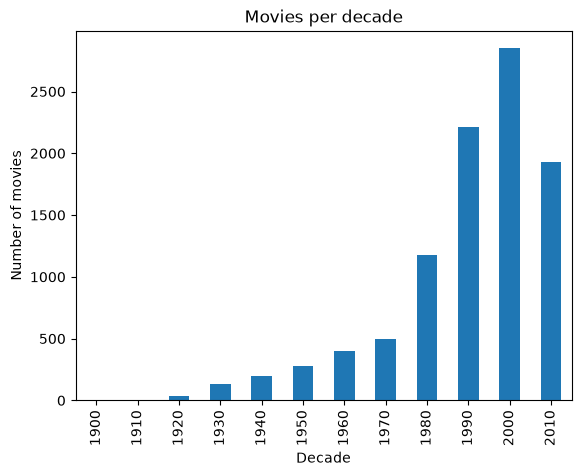

In [9]:
decade = (movies["year"] // 10 * 10).value_counts().sort_index()
decade.plot(kind="bar")
plt.title("Movies per decade")
plt.xlabel("Decade")
plt.ylabel("Number of movies")
plt.show()

## 2. Tags

In [10]:
print("Tag rows:", len(tags))
print("Users who wrote tags:", tags["userId"].nunique())
print("Movies with at least one tag:", tags["movieId"].nunique(),
      f"({tags['movieId'].nunique() / len(movies):.1%} of all movies)")
tags.head()

Tag rows: 3683
Users who wrote tags: 58
Movies with at least one tag: 1572 (16.1% of all movies)


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


In [11]:
# Normalise the text first, so "Sci-Fi" and "sci-fi" count as the same tag
tags["tag"] = tags["tag"].str.lower().str.strip()
tags["tag"].value_counts().head(15)

tag
in netflix queue      131
atmospheric            41
funny                  24
superhero              24
surreal                24
thought-provoking      24
sci-fi                 23
disney                 23
quirky                 22
religion               22
dark comedy            21
suspense               21
psychology             21
twist ending           20
visually appealing     20
Name: count, dtype: int64

In [12]:
# How many tags does a tagged movie have?
tags.groupby("movieId").size().describe()

count    1572.000000
mean        2.342875
std         5.562342
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       181.000000
dtype: float64

## 3. Links (to TMDB)

In [13]:
print("Movies without a tmdbId:", links["tmdbId"].isna().sum())
links.head()

Movies without a tmdbId: 8


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


## 4. Do the rarely rated movies have content?

In notebook 01 we saw that half of the movies have 3 ratings or fewer. Collaborative filtering knows almost nothing about them, so the content-based model has to. Here we check which content source actually *covers* them.

In [14]:
ratings_per_movie = ratings.groupby("movieId").size()

# Movies with 0 ratings do not appear in ratings_per_movie, so they are not in this group
rare_ids = ratings_per_movie[ratings_per_movie <= 3].index
rare = movies[movies["movieId"].isin(rare_ids)]
has_tmdb = links.dropna(subset=["tmdbId"])["movieId"]


def coverage(df):
    """Number of movies and the share that has each kind of content."""
    return pd.Series(
        {
            "movies": len(df),
            "share with genres": (df["genres"] != NO_GENRES).mean(),
            "share with tags": df["movieId"].isin(tags["movieId"]).mean(),
            "share with tmdbId": df["movieId"].isin(has_tmdb).mean(),
        }
    )


pd.DataFrame(
    {"all movies": coverage(movies), "rarely rated (<= 3 ratings)": coverage(rare)}
).round(3)

,all movies,rarely rated (<= 3 ratings)
movies,9742.000,5544.000
share with genres,0.997,0.994
share with tags,0.161,0.065
share with tmdbId,0.999,0.999


## Findings

- **Genres are our backbone.** There are 19 genres, and only 34 movies (0.3%) have none. A typical movie has 2 or 3 genres. Drama (4,361 movies) and Comedy (3,756) dominate; Film-Noir (87) and IMAX (158) are rare.
- **The year is easy to get.** It is in the title for all but 13 movies (for example `Babylon 5`, `Ready Player One`). Those 13 can be fixed by hand or left empty.
- **Tags are sparse and noisy.** Only 58 users wrote tags, covering just 16.1% of movies, and a tagged movie usually has a single tag (median 1). The most common tag, `in netflix queue` (131 times), says nothing about the movie's content, so it needs to be dropped before use.
- **Links are almost complete.** Only 8 movies have no `tmdbId`, so plot descriptions from TMDB are available for 99.9% of the movies.
- **The cold-start check decides the design.** Of the 5,544 movies with 3 ratings or fewer, 99.4% have genres and 99.9% have a `tmdbId`, but only **6.5% have a tag**. Tags cannot help the movies that need help most; genres and TMDB plot text can.

## Feature plan for the content-based model

| Feature | Source | Coverage of rarely rated movies | How we use it |
|---|---|---|---|
| Genres | `movies.csv` | 99.4% | 0/1 column per genre (multi-hot) |
| Plot overview | TMDB API through `links.csv` | 99.9% | TF-IDF on the text; fetched once and cached in `data/processed/` (git-ignored) |
| Release year | title in `movies.csv` | all but 13 movies | decade or scaled number (optional) |
| Tags | `tags.csv` | 6.5% | extra text where available, after dropping noise like `in netflix queue` (optional) |

**Next steps:** (1) a script that fetches the plot overviews and caches them (needs a TMDB API key in `.env`), (2) `src/content_features.py` to build the feature matrix, (3) cosine similarity between movies, checked by looking at the most similar movies to a few known titles.